# Nhận diện khuôn mặt thời gian thực với MTCNN và FaceNet

## 1. Giới thiệu

Hệ thống dùng OpenCV, MTCNN và FaceNet: phát hiện khuôn mặt từ khung hình webcam, căn chỉnh, trích xuất vector đặc trưng 128 chiều rồi so với khuôn mặt tham chiếu bằng độ tương đồng cosine.

**Quy tắc quyết định:** similarity > 0.7 → `Matched`; ngược lại → `Unknown`.

**Quy trình:** Webcam/Ảnh → MTCNN → Căn chỉnh mặt → FaceNet (128D) → Cosine → Matched / Unknown

**Phạm vi notebook:** đánh giá từng bước trên ảnh tĩnh (gồm 1 ảnh tham chiếu và 2 ảnh kiểm thử):

1. Phát hiện mặt và điểm mốc (MTCNN)
2. Căn chỉnh mặt
3. Trích xuất đặc trưng (FaceNet)
4. So khớp bằng cosine
5. Đối chứng: có và không căn chỉnh

Giả định: cả 3 ảnh là **cùng một người**.

## 2. Môi trường và dữ liệu

### 2.1. Thiết lập

Notebook dùng lại các module trong `src/`, không cài đặt lại thuật toán.

In [54]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("ROOT:", ROOT)
print("Reference path:", ROOT / "data/reference/my_face.jpg")

Current directory: c:\Users\NAO\Downloads\lab5_face_ID\document
ROOT: C:\Users\NAO\Downloads\lab5_face_ID
Reference path: C:\Users\NAO\Downloads\lab5_face_ID\data\reference\my_face.jpg


In [33]:
from pathlib import Path

print("Reference:", (ROOT / "data/reference/my_face.jpg").is_file())

print("\nFiles in data/reference:")
for path in (ROOT / "data/reference").glob("*"):
    print(path.name)

print("\nFiles in data/evaluation:")
for path in (ROOT / "data/evaluation").glob("*"):
    print(path.name)

Reference: False

Files in data/reference:
image.jpg
person_01.jpg
person_02.jpg

Files in data/evaluation:
image1.jpg
image2.jpg


In [28]:
# Standard library
import sys
from pathlib import Path

# Third-party libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Project modules
from src.config import REFERENCE_PATH, SIMILARITY_THRESHOLD
from src.face_detector import FaceDetector
from src.face_alignment import align_face
from src.face_embedder import FaceEmbedder
from src.face_matcher import FaceMatcher
from src.visualizer import draw_results

### 2.2. Dữ liệu

| Tên | Tệp | Đặc điểm |
|---|---|---|
| Reference | `data/reference/image.jpg` | Ảnh tham chiếu, đầu nghiêng, nền tường |
| Test 1 | `data/evaluation/image1.jpg` | Nhìn thẳng, ánh sáng sân khấu, có logo và banner quảng cáo |
| Test 2 | `data/evaluation/image2.jpg` | Đeo kính, một tay chạm gọng kính, nền tối |

Ảnh được đọc bằng OpenCV (BGR), chỉ đổi sang RGB khi hiển thị bằng Matplotlib.

In [34]:
IMAGE_PATHS = {
    "Reference": ROOT / "data/reference/image.jpg",
    "Test 1": ROOT / "data/evaluation/image1.jpg",
    "Test 2": ROOT / "data/evaluation/image2.jpg",
}

for name, path in IMAGE_PATHS.items():
    assert path.is_file(), f"Image not found: {path}"
    print(f"{name}: FOUND")

Reference: FOUND
Test 1: FOUND
Test 2: FOUND


In [35]:
# Nạp ảnh
images = {}

for name, path in IMAGE_PATHS.items():
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    images[name] = image

    print(f"{name}: {image.shape}")

Reference: (447, 447, 3)
Test 1: (640, 480, 3)
Test 2: (447, 447, 3)


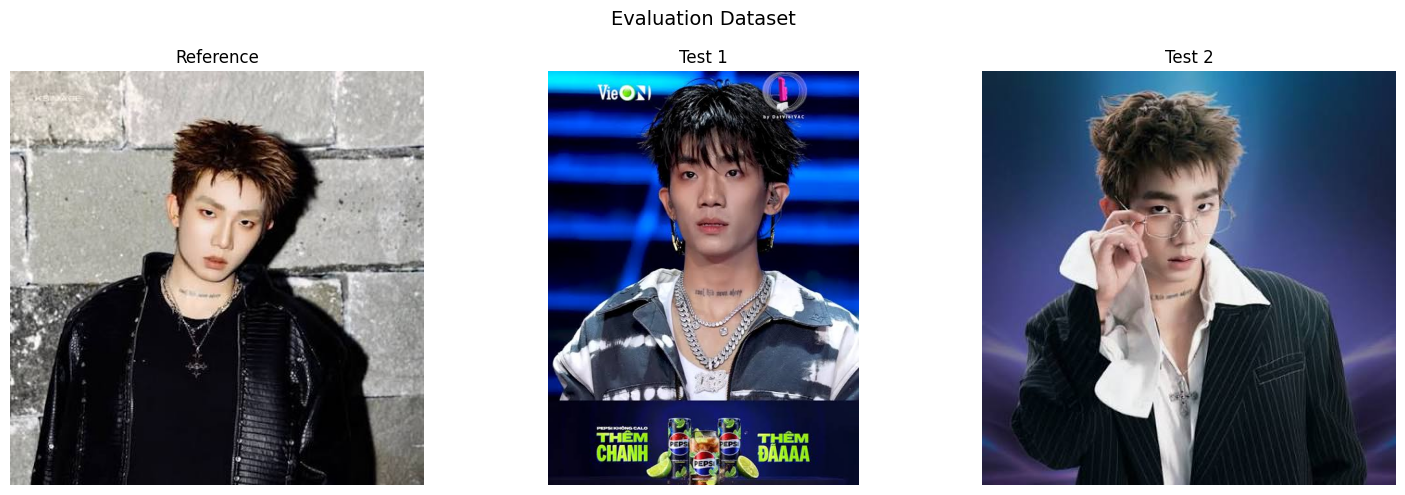

In [36]:
# Trực quan hóa ảnh đầu vào
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, image) in zip(axes, images.items()):
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(rgb_image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Evaluation Dataset", fontsize=14)
plt.tight_layout()
plt.show()

**Nhận xét:** Cả 3 ảnh được nạp thành công. Hai ảnh kiểm thử khác ảnh tham chiếu về nền, ánh sáng và phụ kiện (kính), nên phép thử gần với điều kiện thực tế hơn so với ảnh chụp cùng bối cảnh.

## 3. Phát hiện khuôn mặt bằng MTCNN

### 3.1. Phương pháp

MTCNN trả về với mỗi khuôn mặt:

- **Hộp bao** `(x, y, w, h)`
- **Độ tin cậy** của phát hiện
- **5 điểm mốc:** mắt trái, mắt phải, mũi, hai khóe miệng

Các điểm mốc được dùng để căn chỉnh mặt ở Mục 4.

In [37]:
detector = FaceDetector()

detection_results = {}

for name, image in images.items():
    faces = detector.detect(image)
    detection_results[name] = faces

    print(f"\n{name}: {len(faces)} face(s) detected")

    for i, face in enumerate(faces):
        print(f"  Face {i + 1}")
        print(f"  Box: {face['box']}")
        print(f"  Confidence: {face['confidence']:.4f}")
        print(f"  Keypoints: {face['keypoints']}")

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "c:\Users\NAO\Downloads\lab5_face_ID\.venv\Lib\site-packages\lz4\frame\__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "c:\Users\NAO\Downloads\lab5_face_ID\.venv\Lib\site-packages\lz4\frame\__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "c:\Users\NAO\Downloads\lab5_face_ID\.venv\Lib\site-packages\lz4\frame\__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.



Reference: 1 face(s) detected
  Face 1
  Box: [187, 103, 86, 127]
  Confidence: 0.9893
  Keypoints: {'nose': [np.int64(231), np.int64(186)], 'mouth_right': [np.int64(236), np.int64(206)], 'right_eye': [np.int64(255), np.int64(164)], 'left_eye': [np.int64(216), np.int64(153)], 'mouth_left': [np.int64(209), np.int64(200)]}

Test 1: 1 face(s) detected
  Face 1
  Box: [183, 97, 142, 185]
  Confidence: 0.9998
  Keypoints: {'nose': [np.int64(252), np.int64(198)], 'mouth_right': [np.int64(278), np.int64(237)], 'right_eye': [np.int64(285), np.int64(157)], 'left_eye': [np.int64(219), np.int64(159)], 'mouth_left': [np.int64(228), np.int64(236)]}

Test 2: 1 face(s) detected
  Face 1
  Box: [157, 95, 97, 138]
  Confidence: 0.9999
  Keypoints: {'nose': [np.int64(220), np.int64(181)], 'mouth_right': [np.int64(228), np.int64(202)], 'right_eye': [np.int64(236), np.int64(147)], 'left_eye': [np.int64(192), np.int64(150)], 'mouth_left': [np.int64(200), np.int64(204)]}


3.3. Experimental Results

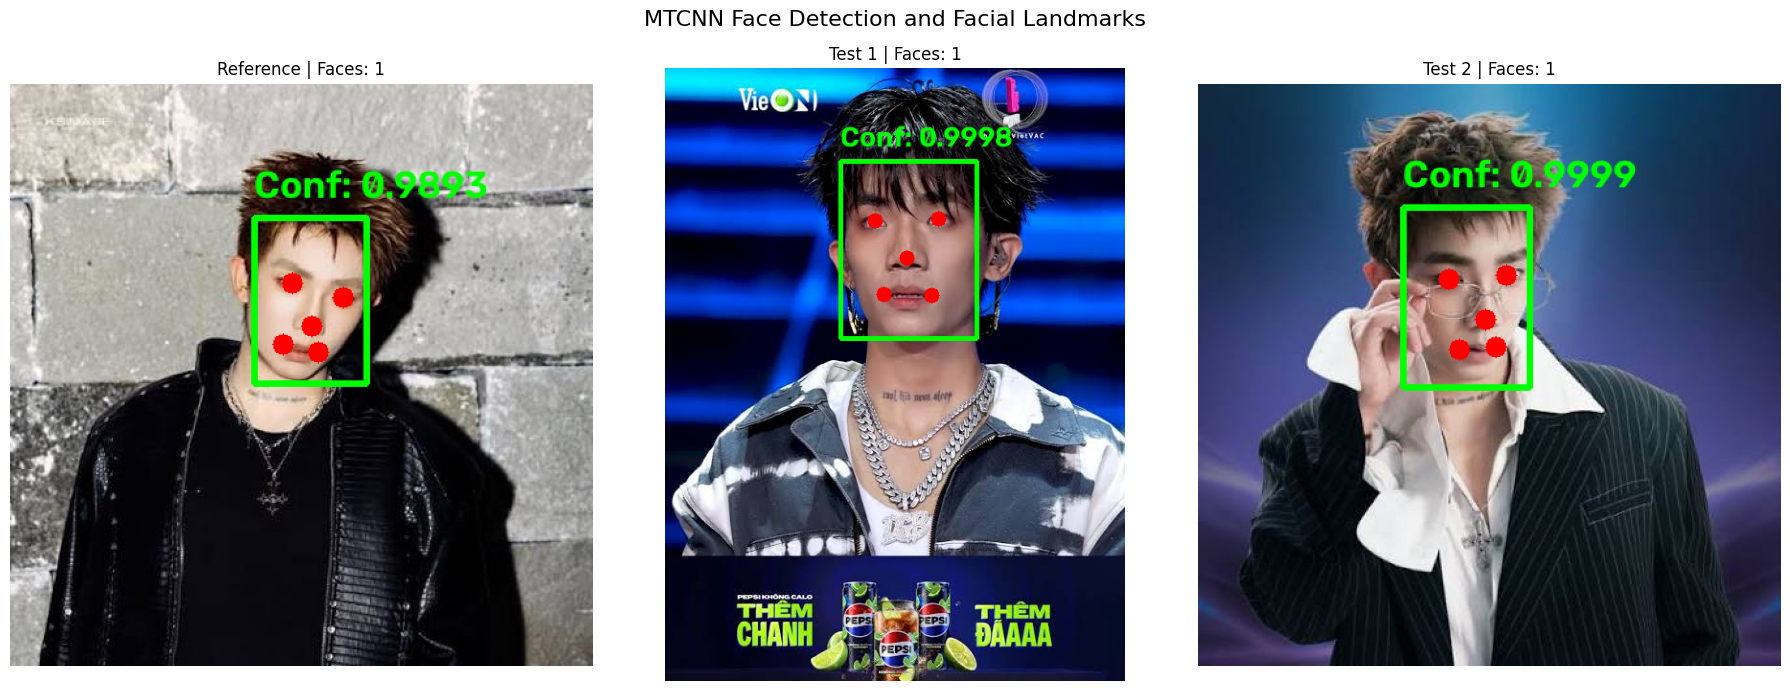

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (name, image) in zip(axes, images.items()):
    display = image.copy()

    for face in detection_results[name]:
        x, y, w, h = map(int, face["box"])
        confidence = float(face["confidence"])

        # Bounding box
        cv2.rectangle(
            display,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

        # Detection confidence
        cv2.putText(
            display,
            f"Conf: {confidence:.4f}",
            (x, max(y - 15, 30)),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            3
        )

        # Five facial landmarks
        for point in face["keypoints"].values():
            px, py = map(int, point)
            cv2.circle(display, (px, py), 8, (0, 0, 255), -1)

    display_rgb = cv2.cvtColor(display, cv2.COLOR_BGR2RGB)

    ax.imshow(display_rgb)
    ax.set_title(
        f"{name} | Faces: {len(detection_results[name])}"
    )
    ax.axis("off")

plt.suptitle("MTCNN Face Detection and Facial Landmarks", fontsize=16)
plt.tight_layout()
plt.show()

Nhận xét

MTCNN phát hiện đúng 1 khuôn mặt ở cả 3 ảnh. Độ tin cậy: Reference **0.9893**, Test 1 **0.9998**, Test 2 **0.9999**.

Logo, banner (Test 1) và kính, bàn tay (Test 2) không gây phát hiện nhầm hay làm mất điểm mốc. Reference có độ tin cậy thấp nhất, có thể do đầu nghiêng và khuôn mặt nhỏ hơn. Kết quả chỉ trên 3 ảnh nên chưa phản ánh độ chính xác tổng quát.

## 4. Căn chỉnh khuôn mặt

### 4.1. Phương pháp

Dùng hai điểm mốc mắt để xoay ảnh bù độ nghiêng đầu, rồi cắt vùng mặt làm đầu vào cho FaceNet:

1. Lấy toạ độ hai mắt.
2. Tính góc giữa hai mắt.
3. Xoay ảnh để hai mắt nằm ngang.
4. Cắt vùng mặt.

### 4.2. Kết quả

In [39]:
aligned_faces = {}
original_faces = {}

for name, image in images.items():
    faces = detection_results[name]

    if len(faces) == 0:
        print(f"{name}: No face detected")
        continue

    # Chọn khuôn mặt có confidence cao nhất
    face = max(faces, key=lambda f: f["confidence"])

    x, y, w, h = map(int, face["box"])

    # Giới hạn tọa độ trong kích thước ảnh
    height, width = image.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)

    original_crop = image[y1:y2, x1:x2].copy()

    # Gọi module alignment của project
    aligned_crop = align_face(image, face)

    if original_crop.size == 0 or aligned_crop is None or aligned_crop.size == 0:
        print(f"{name}: Invalid face crop")
        continue

    original_faces[name] = original_crop
    aligned_faces[name] = aligned_crop

    print(f"{name}")
    print(f"  Original shape: {original_crop.shape}")
    print(f"  Aligned shape:  {aligned_crop.shape}")

Reference
  Original shape: (127, 86, 3)
  Aligned shape:  (147, 119, 3)
Test 1
  Original shape: (185, 142, 3)
  Aligned shape:  (191, 148, 3)
Test 2
  Original shape: (138, 97, 3)
  Aligned shape:  (145, 107, 3)


### 4.3. Visualization

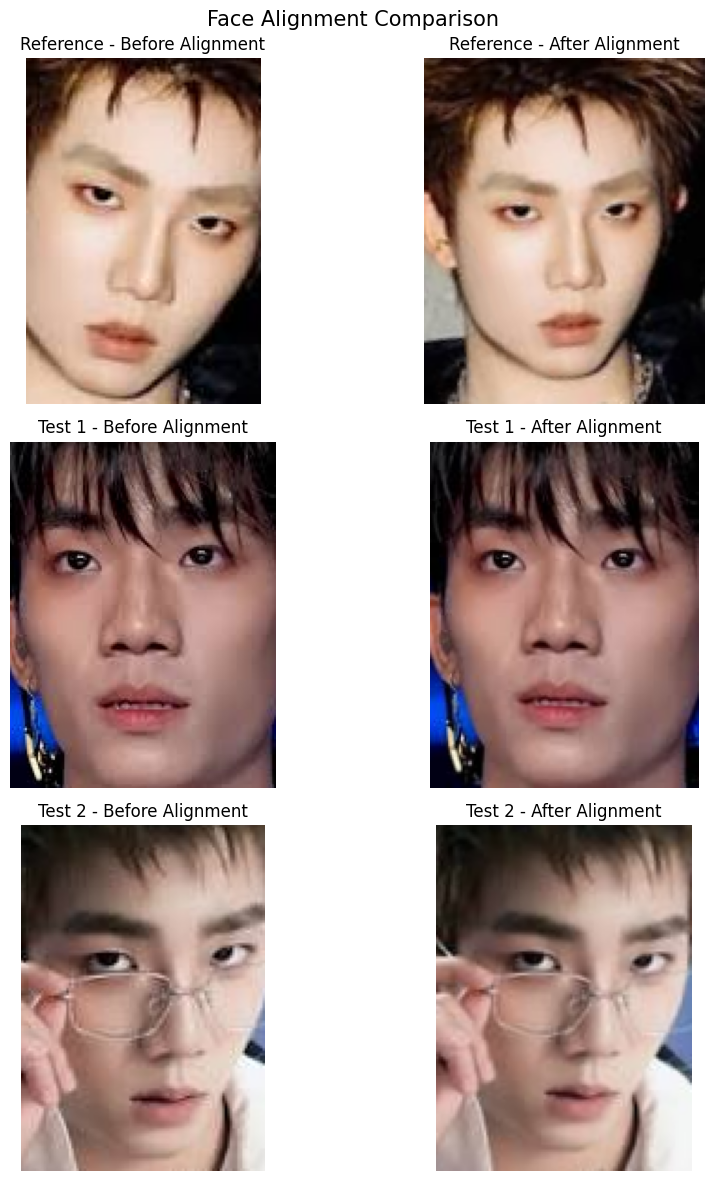

In [40]:
names = list(aligned_faces.keys())

fig, axes = plt.subplots(
    len(names), 2,
    figsize=(10, 4 * len(names)),
    squeeze=False
)

for i, name in enumerate(names):
    before = original_faces[name]
    after = aligned_faces[name]

    axes[i, 0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{name} - Before Alignment")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{name} - After Alignment")
    axes[i, 1].axis("off")

plt.suptitle("Face Alignment Comparison", fontsize=15)
plt.tight_layout()
plt.show()

### 4.4. Kiểm tra góc nghiêng hai mắt

In [41]:
angles = {}

for name, faces in detection_results.items():
    if not faces:
        continue

    face = max(faces, key=lambda f: f["confidence"])

    left_eye = np.array(face["keypoints"]["left_eye"], dtype=float)
    right_eye = np.array(face["keypoints"]["right_eye"], dtype=float)

    dx = right_eye[0] - left_eye[0]
    dy = right_eye[1] - left_eye[1]

    angle = np.degrees(np.arctan2(dy, dx))
    angles[name] = angle

    print(f"{name}: Eye-line angle = {angle:.2f} degrees")

Reference: Eye-line angle = 15.75 degrees
Test 1: Eye-line angle = -1.74 degrees
Test 2: Eye-line angle = -3.90 degrees


Nhận xét

Góc nghiêng hai mắt: Reference **15.75°**, Test 1 **−1.74°**, Test 2 **−3.90°**. Chỉ ảnh tham chiếu bị nghiêng rõ, hai ảnh kiểm thử gần như thẳng.

Sau căn chỉnh, vùng cắt lớn hơn bản gốc (ví dụ Reference từ 127×86 lên 147×119). Vì vậy kết quả ở Mục 7 phản ánh cả việc xoay lẫn thay đổi cách cắt.

## 5. Trích xuất đặc trưng bằng FaceNet

### 5.1. Phương pháp

FaceNet (đã huấn luyện sẵn) biến mỗi khuôn mặt đã căn chỉnh thành vector **128 chiều**. Module `FaceEmbedder` xử lý tiền xử lý và suy luận.

### 5.2. Kết quả

In [42]:
embedder = FaceEmbedder()

embeddings = {}

for name, face_image in aligned_faces.items():
    embedding = embedder.extract(face_image)

    embeddings[name] = embedding

    print(f"\n{name}")
    print(f"  Shape: {embedding.shape}")
    print(f"  Dtype: {embedding.dtype}")
    print(f"  L2 norm: {np.linalg.norm(embedding):.4f}")
    print(f"  First 5 values: {embedding[:5]}")


Reference
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.7353
  First 5 values: [ 0.36203086 -0.57210565 -1.0572591  -0.61369514  1.1165558 ]

Test 1
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.9147
  First 5 values: [ 1.3181329  -0.62871397 -2.3095229   0.64889026  0.05132625]

Test 2
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.3956
  First 5 values: [ 1.1615671  -0.43416965 -1.0413629  -0.6723674   0.17400444]


In [43]:
for name, embedding in embeddings.items():
    assert embedding.shape == (128,), f"{name}: Invalid embedding shape"
    assert np.all(np.isfinite(embedding)), f"{name}: Non-finite values"

    print(f"{name}: PASS")

Reference: PASS
Test 1: PASS
Test 2: PASS


5.3. Visualization — Biểu diễn vector đặc trưng

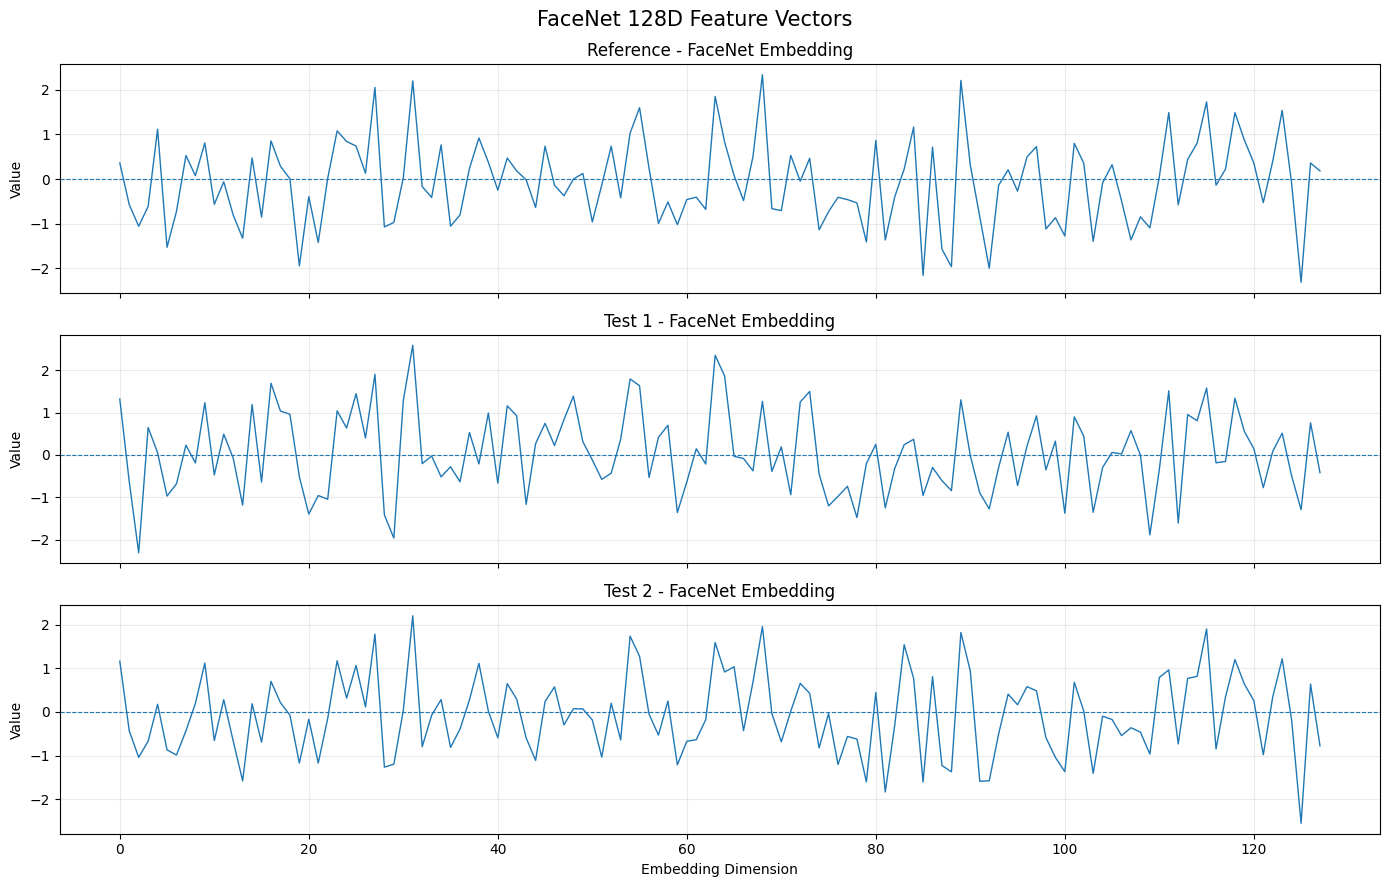

In [44]:
fig, axes = plt.subplots(
    len(embeddings), 1,
    figsize=(14, 9),
    sharex=True,
    squeeze=False
)

for ax, (name, embedding) in zip(axes.flat, embeddings.items()):
    ax.plot(np.arange(128), embedding, linewidth=1)
    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set_title(f"{name} - FaceNet Embedding")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.25)

axes[-1, 0].set_xlabel("Embedding Dimension")
plt.suptitle("FaceNet 128D Feature Vectors", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét

Cả 3 vector có kích thước `(128,)`, giá trị hữu hạn. Chuẩn L2 khoảng 10.4–10.9 (vector chưa chuẩn hóa), không ảnh hưởng đến cosine vì cosine chỉ xét hướng. Từng chiều riêng lẻ không có ý nghĩa trực quan; cần so sánh hai vector bằng độ đo cosine (Mục 6).

## 6. So khớp bằng độ tương đồng cosine

### 6.1. Phương pháp

Cosine đo góc giữa hai vector đặc trưng. Vector tham chiếu được so với vector của Test 1 và Test 2.

- similarity > 0.7 → `Matched`
- similarity ≤ 0.7 → `Unknown`

Ngưỡng 0.7 do đề bài quy định, chưa được tối ưu bằng dữ liệu kiểm định.

### 6.2. Kết quả

In [46]:
reference_embedding = embeddings["Reference"]

similarity_results = {}

for name, test_embedding in embeddings.items():

    if name == "Reference":
        continue

    similarity = float(
        np.dot(reference_embedding, test_embedding)
        / (
            np.linalg.norm(reference_embedding)
            * np.linalg.norm(test_embedding)
        )
    )

    label = (
        "Matched"
        if similarity >= SIMILARITY_THRESHOLD
        else "Unknown"
    )

    similarity_results[name] = {
        "similarity": similarity,
        "label": label
    }

    print(f"{name}: {similarity:.4f} → {label}")

Test 1: 0.7053 → Matched
Test 2: 0.8918 → Matched


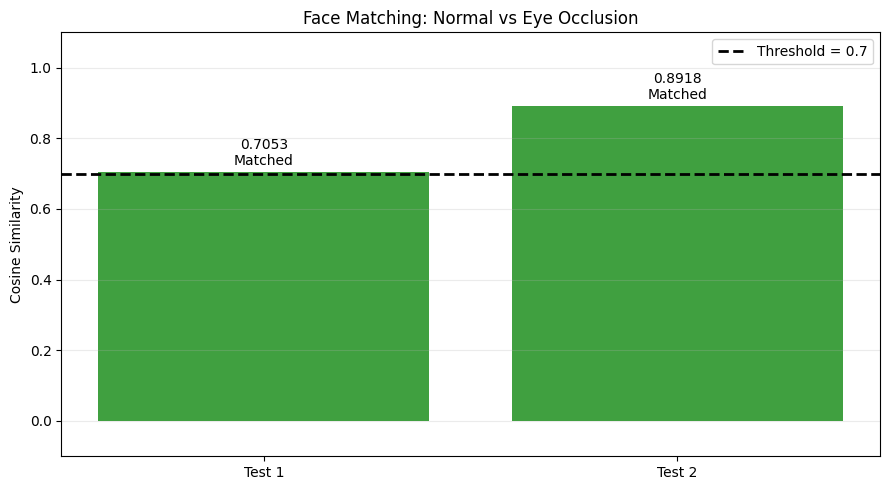

In [47]:
names = list(similarity_results.keys())

scores = [
    similarity_results[name]["similarity"]
    for name in names
]

labels = [
    similarity_results[name]["label"]
    for name in names
]

colors = [
    "green" if label == "Matched" else "red"
    for label in labels
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(names, scores, color=colors, alpha=0.75)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

for bar, score, label in zip(bars, scores, labels):
    ax.annotate(
        f"{score:.4f}\n{label}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylabel("Cosine Similarity")
ax.set_title("Face Matching: Normal vs Eye Occlusion")
ax.set_ylim(min(-0.1, min(scores) - 0.15), 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Nhận xét

| Ảnh | Cosine | Kết quả |
|---|---|---|
| Test 1 | 0.7053 | Matched |
| Test 2 | 0.8918 | Matched |

Cả hai ảnh đều được nhận đúng. Test 2 đeo kính vẫn đạt 0.8918, cao hơn ngưỡng rõ rệt.

Test 1 chỉ vượt ngưỡng **0.0053**, nên kết quả rất sát biên: một thay đổi nhỏ (ánh sáng, biểu cảm, cách cắt mặt) có thể đẩy xuống dưới 0.7 thành `Unknown`. Nguyên nhân điểm thấp hơn Test 2 có thể là ánh sáng sân khấu và kiểu tóc khác ảnh tham chiếu, nhưng chưa được kiểm chứng. Kết quả chỉ áp dụng cho các ảnh đã chọn.

## 7. Thí nghiệm đối chứng: ảnh hưởng của căn chỉnh

### 7.1. Thiết kế

So sánh hai cấu hình, cùng ảnh, cùng mô hình, cùng ngưỡng 0.7:

- **Có căn chỉnh:** MTCNN → căn chỉnh → FaceNet → cosine
- **Không căn chỉnh:** MTCNN → cắt mặt → FaceNet → cosine

### 7.2. Kết quả

In [48]:
embeddings_no_alignment = {}

for name, face_image in original_faces.items():
    embedding = embedder.extract(face_image)

    assert embedding.shape == (128,)
    assert np.all(np.isfinite(embedding))

    embeddings_no_alignment[name] = embedding

    print(f"{name}: {embedding.shape} - PASS")

Reference: (128,) - PASS
Test 1: (128,) - PASS
Test 2: (128,) - PASS


In [50]:
ablation_results = {}

ref = embeddings_no_alignment["Reference"]

for name in similarity_results.keys():

    # With alignment: kết quả từ Section 6
    sim_aligned = similarity_results[name]["similarity"]

    # Without alignment
    test = embeddings_no_alignment[name]

    sim_no_alignment = float(
        np.dot(ref, test)
        / (
            np.linalg.norm(ref)
            * np.linalg.norm(test)
        )
    )

    ablation_results[name] = {
        "With Alignment": sim_aligned,
        "Without Alignment": sim_no_alignment,
        "Difference": sim_aligned - sim_no_alignment
    }

    print(
        f"{name}: "
        f"Aligned = {sim_aligned:.4f} | "
        f"No Alignment = {sim_no_alignment:.4f} | "
        f"Difference = {sim_aligned - sim_no_alignment:+.4f}"
    )

Test 1: Aligned = 0.7053 | No Alignment = 0.6036 | Difference = +0.1018
Test 2: Aligned = 0.8918 | No Alignment = 0.8038 | Difference = +0.0881


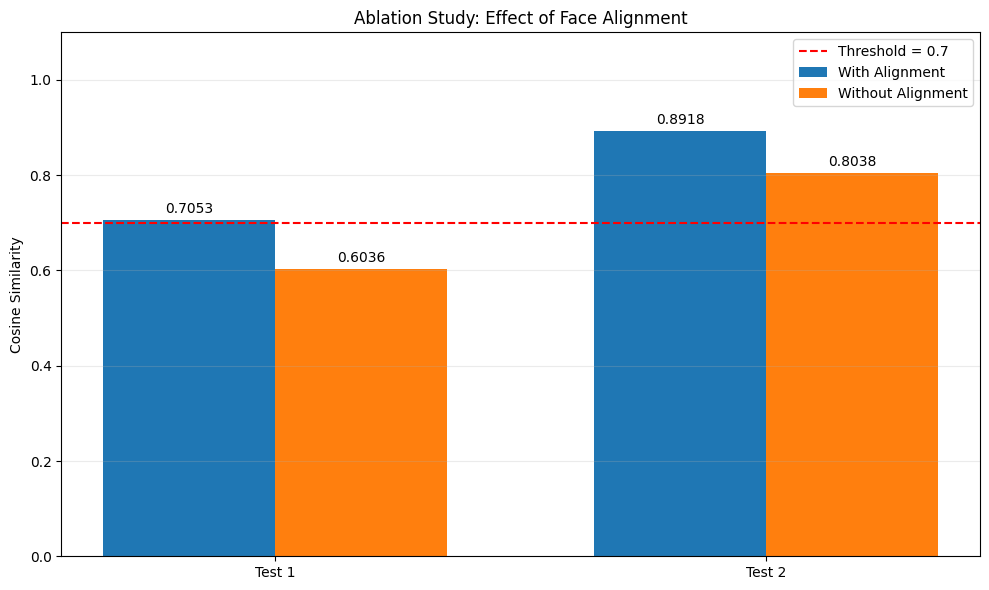

In [51]:
names = list(ablation_results.keys())

with_alignment = [
    ablation_results[name]["With Alignment"]
    for name in names
]

without_alignment = [
    ablation_results[name]["Without Alignment"]
    for name in names
]

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    with_alignment,
    width,
    label="With Alignment"
)

bars2 = ax.bar(
    x + width / 2,
    without_alignment,
    width,
    label="Without Alignment"
)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="red",
    linestyle="--",
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Cosine Similarity")
ax.set_title("Ablation Study: Effect of Face Alignment")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Nhận xét

| Ảnh | Không căn chỉnh | Có căn chỉnh | Chênh lệch | Kết quả (không → có) |
|---|---|---|---|---|
| Test 1 | 0.6036 | 0.7053 | +0.1018 | Unknown → Matched |
| Test 2 | 0.8038 | 0.8918 | +0.0881 | Matched → Matched |

Căn chỉnh làm tăng điểm cosine ở cả hai ảnh (khoảng +0.09 đến +0.10). Đáng chú ý, ở Test 1 căn chỉnh **làm đổi kết quả** từ `Unknown` sang `Matched`.

Nhiều khả năng do ảnh tham chiếu nghiêng 15.75° (Mục 4.3), nhưng thí nghiệm chưa tách riêng tác động của việc xoay khỏi việc đổi vùng cắt. Với chỉ 2 ảnh, chưa thể kết luận chung.

## 8. Đánh giá tổng hợp và kết luận

### 8.1. Bảng tổng hợp

Cột `Expected` lấy từ biến `ground_truth` trong ô bên dưới (đặt `"Matched"` nếu cùng người với ảnh tham chiếu).

In [53]:
import pandas as pd
from IPython.display import display as show_table

# Ground truth: cập nhật theo danh tính thực tế của từng ảnh
# "Matched": cùng người với ảnh Reference
# "Unknown": người khác với ảnh Reference
ground_truth = {
    "Test 1": None,
    "Test 2": None,
}

summary_rows = []

for name, result in similarity_results.items():

    similarity = result["similarity"]
    prediction = result["label"]
    expected = ground_truth.get(name)

    faces = detection_results.get(name, [])

    detection_confidence = (
        max(face["confidence"] for face in faces)
        if faces else None
    )

    correct = (
        prediction == expected
        if expected is not None
        else None
    )

    summary_rows.append({
        "Test Image": name,
        "Detection Confidence": detection_confidence,
        "Similarity (Aligned)": similarity,
        "Similarity (No Alignment)": ablation_results[name]["Without Alignment"],
        "Prediction": prediction,
        "Expected": expected,
        "Correct": correct
    })

summary_df = pd.DataFrame(summary_rows)

show_table(summary_df.round(4))

,Test Image,Detection Confidence,Similarity (Aligned),Similarity (No Alignment),Prediction,Expected,Correct
0,Test 1,0.9998,0.7053,0.6036,Matched,None,None
1,Test 2,0.9999,0.8918,0.8038,Matched,None,None


### 8.2. Hạn chế

- Chỉ có 1 ảnh tham chiếu và 2 ảnh kiểm thử, giả định cùng một người.
- Chưa có ảnh người lạ nên chưa đánh giá được tỉ lệ chấp nhận nhầm (FAR).
- Ngưỡng 0.7 chưa được tối ưu bằng tập kiểm định.
- Test 1 chỉ hơn ngưỡng 0.0053, kết quả kém ổn định.
- Chưa khảo sát hệ thống về ánh sáng, góc đầu, khoảng cách camera và các kiểu che khuôn mặt.
- Notebook đánh giá trên ảnh tĩnh, chưa gồm phần chạy thời gian thực qua webcam.

Do đó kết quả chỉ mang tính nghiên cứu trường hợp quy mô nhỏ, không phải độ chính xác tổng quát.

### 8.3. Kết luận

Quy trình MTCNN → căn chỉnh → FaceNet 128D → cosine hoạt động đúng trên dữ liệu đánh giá:

- MTCNN phát hiện mặt ở cả 3 ảnh (độ tin cậy 0.9893–0.9999).
- Cả hai ảnh kiểm thử được nhận là `Matched`: Test 1 đạt 0.7053, Test 2 đạt 0.8918.
- Căn chỉnh tăng cosine ở cả hai ảnh; riêng Test 1 chỉ đạt `Matched` nhờ căn chỉnh (0.6036 → 0.7053), nhưng vẫn sát ngưỡng.

### 8.4. Hướng phát triển

- Mở rộng dữ liệu: nhiều người, nhiều điều kiện ánh sáng, góc đầu và kiểu che.
- Thêm ảnh người lạ; đánh giá bằng FAR, FRR và chọn ngưỡng theo tập kiểm định.
- Tách riêng tác động của việc xoay và việc đổi vùng cắt khi đánh giá căn chỉnh.
- Đăng ký nhiều ảnh tham chiếu cho mỗi người; thử mô hình embedding khác.